### Image Classification with Convolutional Neural Networks
### Burkhard Militzer, 10-29-26

#### (1) First we need to install the packages: mytorch, tqdm and seaborn. This may work with the following tree conda commands:
conda install seaborn<br>
conda install pytorch::pytorch torchvision torchaudio -c pytorch<br>
conda install tqdm<br>
#### On a Mac, PyTorch may require us to revert beack to NumPy 1.xx instead the usual 2.xx. If you encounter this problem, we recommend you generate a new Python environment with the following commands in a Terminal window:
conda create --name myPyTorch python=3.13<br>
conda activate myPyTorch<br>
conda install ipykernel<br>
python -m ipykernel install --user --name=myPyTorch --display-name="myPyTorch"<br>
conda install numpy=1.26<br>
conda install matplotlib    <br>
conda install seaborn<br>
conda install pytorch::pytorch torchvision torchaudio -c pytorch<br>
conda install tqdm<br>
#### When you open a new notebook, your will need to select your new environment 'myPyTorch'

In [1]:
# New test if PyTorch can be loaded
import torch
from torch import nn

# Note: this notebook requires torch >= 1.10.0
torch.__version__

'2.14.1+cpu'

In [2]:
# See if the Cuda accelerator is available. There is no cuda for Macs unfortunately but that is ok.
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

#### (2) In this lab, we want to teach your laptop to distinguish between paintings and sculptures with convolutional neural networks (CNN). From bCourses, download your image files:
SID1 = the last digit of your student ID.<br>
SID2 = the penultimate digit of your student ID.<br>
<b>images_for_computer_lab_paintings_7_{SID1}.zip</b><br>
<b>images_for_computer_lab_sculptures_7_{SID2}.zip</b><br>
Unzip these files and check that you have been given images of paintings and sculptures.

#### As you will learn, training a CNN will take considerable computer time and crucially depends on how many images you decide to train and test with. So to start, we recommend you respectively use only 50 and 20 paintings to train and test with. You also need an equal number of sculptures. In short, you will use 2x(50+20) images out of 2x375 that were provided to you.<br>
Since you will be training multiple times, make a new folder classed $dd$ for this training session alone. Then create the following four folders and place the required images inside. You can chose any of the images you like but it is important that you do not use the same images for training and testing:<br>
mkdir dd/training_set/paitings $\;\;\;\;\;\;$ <<<<<< copy 50 paintings inside<br>
mkdir dd/training_set/sculpture $\;\;\;\;$ <<<<<< copy 20 sculptures inside<br>
mkdir dd/test_set/paitings $\;\;\;\;\;\;\;\;\;\;\;\;$ <<<<<< copy 50 paintings inside<br>
mkdir dd/test_set/sculpture $\;\;\;\;\;\;\;\;\;\;$ <<<<<< copy 20 sculptures inside
#### Inside your notebook, change into folder dd


In [3]:
%cd dd

/content/dd


In [4]:
# verify that you are in the correct folder with
%pwd

'/content/dd'

In [5]:
# list all files with
%ls

test_set/  training_set/


In [6]:
# let see if Python can find your folder with
import os
def walk_through_dir(dir_path):
  for dirpath, dirnames, filenames in os.walk(dir_path):
    print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

image_path = "/content/dd"  # modified to Colab path
walk_through_dir(image_path)

There are 3 directories and 0 images in '/content/dd'.
There are 3 directories and 0 images in '/content/dd/training_set'.
There are 0 directories and 0 images in '/content/dd/training_set/.ipynb_checkpoints'.
There are 0 directories and 50 images in '/content/dd/training_set/sculpture'.
There are 0 directories and 50 images in '/content/dd/training_set/paintings'.
There are 0 directories and 0 images in '/content/dd/.ipynb_checkpoints'.
There are 3 directories and 0 images in '/content/dd/test_set'.
There are 0 directories and 0 images in '/content/dd/test_set/.ipynb_checkpoints'.
There are 0 directories and 20 images in '/content/dd/test_set/sculpture'.
There are 0 directories and 20 images in '/content/dd/test_set/paintings'.


In [7]:
# after looking at available directories, now set them explicitly
train_dir = "/content/dd/training_set"
test_dir  = "/content/dd/test_set"
train_dir, test_dir

('/content/dd/training_set', '/content/dd/test_set')

#### (3) Let's try loading images

Random image path: /content/dd/training_set/sculpture/2016_IMG_0603m.jpg
Image class: sculpture
Image height: 4912
Image width: 3214


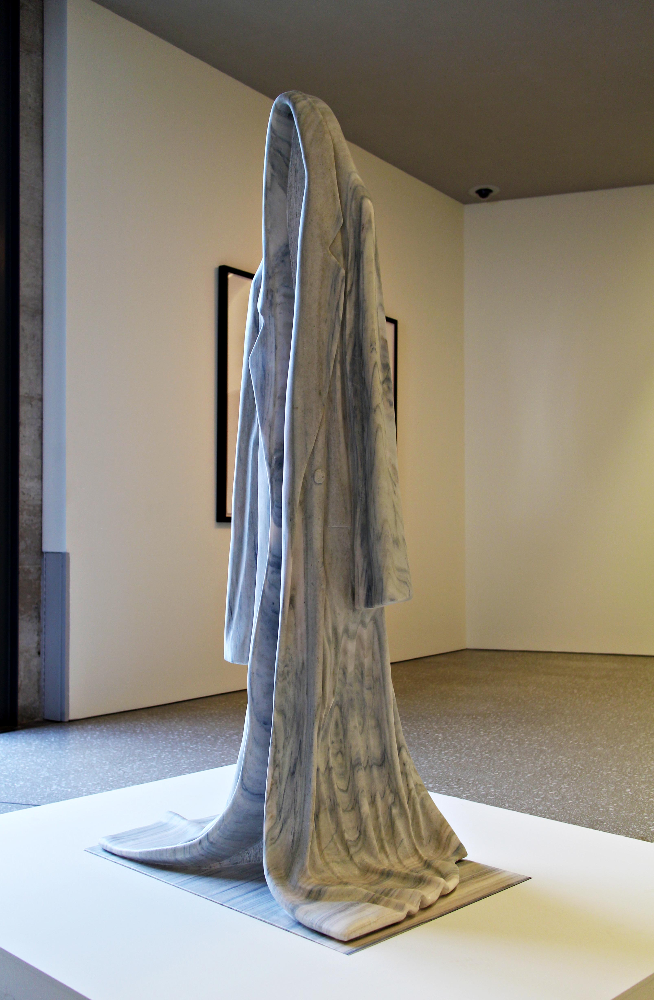

In [8]:
# select one image at random and try reading and displaying it
import random
from PIL import Image
import glob
from pathlib import Path

# Set the random number seed (Does anyone remember why we always set it to 42?)
random.seed(42)

# 1. Get all image paths (* means "any combination")
image_path_list= glob.glob(f"{image_path}/*/*/*.jpg")

# 2. Get random image path
random_image_path = random.choice(image_path_list)

# 3. Get image class from path name (the image class is the name of the directory where the image is stored)
image_class = Path(random_image_path).parent.stem

# 4. Open image
img = Image.open(random_image_path)

# 5. Print metadata
print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}")
print(f"Image width: {img.width}")
img

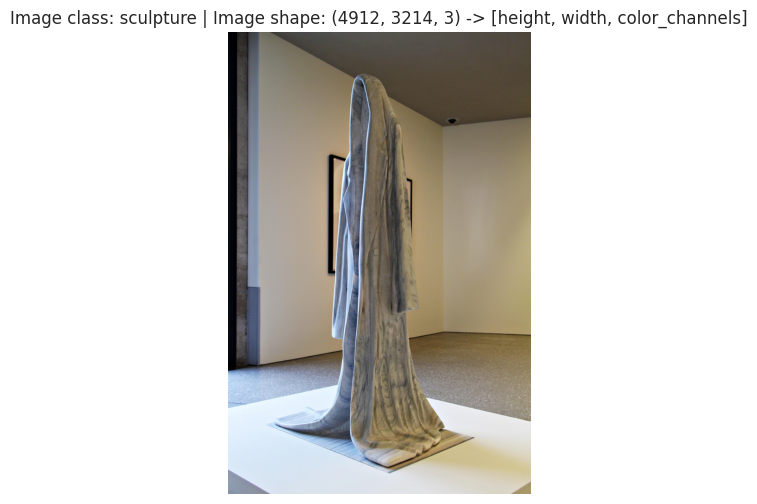

In [9]:
# display the same image again with the 'seaborn' package
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

# Turn the image into an array
img_as_array = np.asarray(img)

# Plot the image with matplotlib
plt.figure(figsize=(8, 6))
plt.imshow(img_as_array)
plt.title(f"Image class: {image_class} | Image shape: {img_as_array.shape} -> [height, width, color_channels]")
plt.axis(False);

In [10]:
# For the training to complete in a reasonable time, we work with rather small images.
# Larger images will not necessarily yield better results. So we recommend you leave
# the image dimensions unchanged. So let's prepare down scaling the images
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

IMAGE_WIDTH =224
IMAGE_HEIGHT=224
IMAGE_SIZE=(IMAGE_WIDTH, IMAGE_HEIGHT)

# Write transform for image
data_transform = transforms.Compose([
    # Resize the images to IMAGE_SIZE xIMAGE_SIZE
    transforms.Resize(size=IMAGE_SIZE),
    # Flip the images randomly on the horizontal
    transforms.RandomHorizontalFlip(p=0.5), # p = probability of flip, 0.5 = 50% chance
    # Turn the image into a torch.Tensor
    transforms.ToTensor() # this also converts all pixel values from 0 to 255 to be between 0.0 and 1.0
])

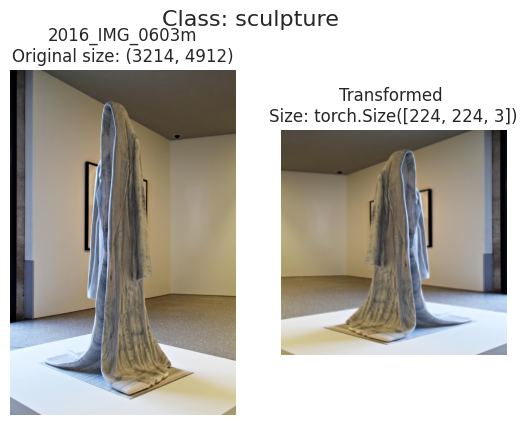

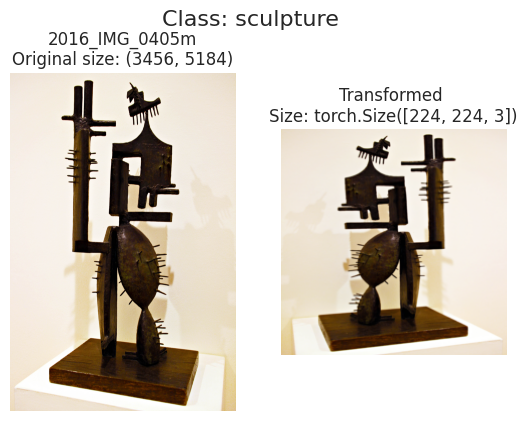

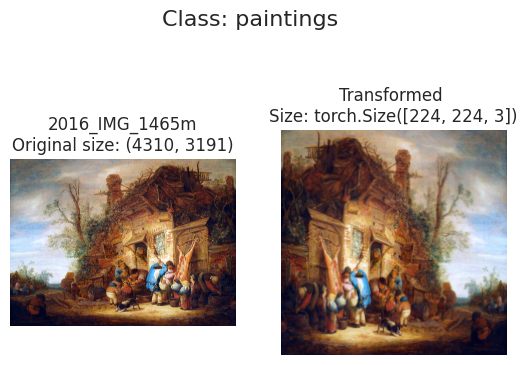

In [11]:
# practice down scaling three images
def plot_transformed_images(image_paths, transform, n=3, seed=42):
    random.seed(seed)
    random_image_paths = random.sample(image_paths, k=n)
    #print(random_image_paths)
    #rint(Path(random_image_path).parent.stem)
    for image_path in random_image_paths:
        #print(image_path)
        #print(Path(image_path).stem)
        with Image.open(image_path) as f:
            fig, ax = plt.subplots(1, 2)
            ax[0].imshow(f)
            ax[0].set_title(f"{Path(image_path).stem}\nOriginal size: {f.size}")
            ax[0].axis("off")

            # Transform and plot image
            # Note: permute() will change shape of image to suit matplotlib
            # (PyTorch default is [C, H, W] but Matplotlib is [H, W, C])
            transformed_image = transform(f).permute(1, 2, 0)
            ax[1].imshow(transformed_image)
            ax[1].set_title(f"Transformed \nSize: {transformed_image.shape}")
            ax[1].axis("off")
            #fig.suptitle(f"Class: {Path(random_image_path).parent.stem}", fontsize=16) # bug
            fig.suptitle(f"Class: {Path(image_path).parent.stem}", fontsize=16)

plot_transformed_images(image_path_list, transform=data_transform, n=3)

In [15]:
# With TorchVision, generate test and training datasets
import shutil
import os
from torchvision import datasets

# Helper to remove system hidden checkpoint directories that cause ImageFolder to fail
for root, dirs, files in os.walk(train_dir):
    for d in dirs:
        if d == '.ipynb_checkpoints':
            shutil.rmtree(os.path.join(root, d))

for root, dirs, files in os.walk(test_dir):
    for d in dirs:
        if d == '.ipynb_checkpoints':
            shutil.rmtree(os.path.join(root, d))

# Creating training set
train_data = datasets.ImageFolder(root=train_dir, # target folder of images
                                  transform=data_transform, # transforms to perform on data (images)
                                  target_transform=None) # transforms to perform on labels (if necessary)
#Creating test set
test_data = datasets.ImageFolder(root=test_dir, transform=data_transform)

print(f"Train data:\n{train_data}\nTest data:\n{test_data}")

Train data:
Dataset ImageFolder
    Number of datapoints: 100
    Root location: /content/dd/training_set
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )
Test data:
Dataset ImageFolder
    Number of datapoints: 40
    Root location: /content/dd/test_set
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )


In [16]:
# Get class names as a list
# In this example, it should be paitings and sculptures
class_names = train_data.classes
print("Class names: ",class_names)

# Can also get class names as a dict
class_dict = train_data.class_to_idx
print("Class names as a dict: ",class_dict)

# Check the lengths
print("The lengths of the training and test sets: ", len(train_data), len(test_data))

Class names:  ['paintings', 'sculpture']
Class names as a dict:  {'paintings': 0, 'sculpture': 1}
The lengths of the training and test sets:  100 40


In [17]:
# print the shape of the first image
img, label = train_data[0][0], train_data[0][1]
print(f"Image tensor:\n{img}")
print(f"Image shape: {img.shape}")
print(f"Image datatype: {img.dtype}")
print(f"Image label: {label}")
print(f"Label datatype: {type(label)}")

Image tensor:
tensor([[[0.8549, 0.8902, 0.8706,  ..., 0.8039, 0.7647, 0.7020],
         [0.9333, 0.9451, 0.9412,  ..., 0.8980, 0.8627, 0.7176],
         [0.9490, 0.9490, 0.9451,  ..., 0.8314, 0.8549, 0.7333],
         ...,
         [0.9294, 0.8588, 0.8314,  ..., 0.9020, 0.8549, 0.8824],
         [0.9333, 0.9020, 0.9020,  ..., 0.8745, 0.8588, 0.8941],
         [0.9255, 0.9333, 0.9373,  ..., 0.8275, 0.8510, 0.8941]],

        [[0.7961, 0.8510, 0.8275,  ..., 0.8000, 0.7451, 0.6784],
         [0.9176, 0.9333, 0.9255,  ..., 0.8980, 0.8471, 0.7059],
         [0.9373, 0.9333, 0.9176,  ..., 0.8392, 0.8510, 0.7098],
         ...,
         [0.9137, 0.8314, 0.8078,  ..., 0.8549, 0.7804, 0.8588],
         [0.9255, 0.8980, 0.8784,  ..., 0.8000, 0.7961, 0.8627],
         [0.9098, 0.9255, 0.9176,  ..., 0.7216, 0.7765, 0.8745]],

        [[0.7098, 0.7843, 0.7490,  ..., 0.7882, 0.7569, 0.6627],
         [0.8706, 0.8824, 0.8471,  ..., 0.8863, 0.8314, 0.6863],
         [0.8902, 0.8745, 0.8510,  ..., 0.84

Original shape: torch.Size([3, 224, 224]) -> [color_channels, height, width]
Image permute shape: torch.Size([224, 224, 3]) -> [height, width, color_channels]


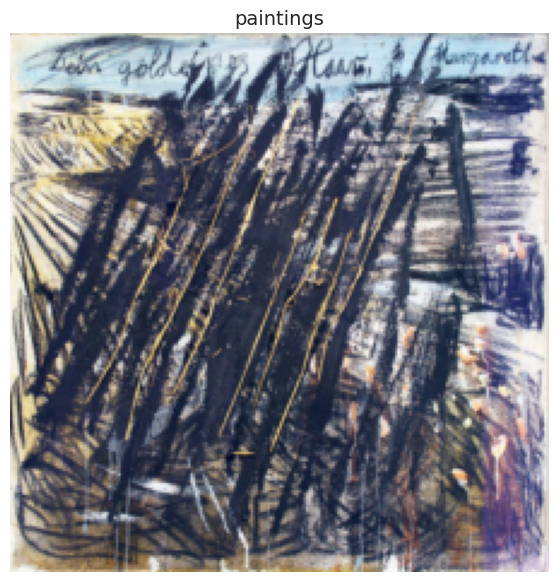

In [18]:
# Re-arrange the order of dimensions and display one image
img_permute = img.permute(1, 2, 0)

# Print out different shapes (before and after permute)
print(f"Original shape: {img.shape} -> [color_channels, height, width]")
print(f"Image permute shape: {img_permute.shape} -> [height, width, color_channels]")

# Plot the image
plt.figure(figsize=(10, 7))
plt.imshow(img.permute(1, 2, 0))
plt.axis("off")
plt.title(class_names[label], fontsize=14);

#### (4) Loading the images

In [19]:
from torch.utils.data import DataLoader

# How many subprocesses will be used for data loading (higher = more)
NUM_WORKERS = os.cpu_count()
print(NUM_WORKERS)

# Turn train and test Datasets into DataLoaders
train_dataloader = DataLoader(dataset=train_data,
                              batch_size=1, # how many samples per batch?
                              num_workers=NUM_WORKERS,
                              shuffle=True) # shuffle the data?

test_dataloader = DataLoader(dataset=test_data,
                             batch_size=1,
                             num_workers=NUM_WORKERS,
                             shuffle=False) # don't usually need to shuffle testing data

train_dataloader, test_dataloader

2


(<torch.utils.data.dataloader.DataLoader at 0x793dc2f7f4d0>,
 <torch.utils.data.dataloader.DataLoader at 0x793d637e1450>)

In [20]:
# following may take a minute to run
img, label = next(iter(train_dataloader))

# Note that batch size will now be 1.
print(f"Image shape: {img.shape} -> [batch_size, color_channels, height, width]")
print(f"Label shape: {label.shape}")

Image shape: torch.Size([1, 3, 224, 224]) -> [batch_size, color_channels, height, width]
Label shape: torch.Size([1])


In [21]:
# Use variables defined above, do not reset them
IMAGE_SIZE=(IMAGE_WIDTH, IMAGE_HEIGHT)

# Create training transform with TrivialAugment
train_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor()])

# Create testing transform (no data augmentation)
test_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor()])

In [22]:
# Turn image folders into Datasets using the correct Colab path variables
from torchvision import transforms, datasets

IMAGE_SIZE = (224, 224)

train_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor()
])

train_data_augmented = datasets.ImageFolder(train_dir, transform=train_transform)
test_data_augmented = datasets.ImageFolder(test_dir, transform=test_transform)

train_data_augmented, test_data_augmented

(Dataset ImageFolder
     Number of datapoints: 100
     Root location: /content/dd/training_set
     StandardTransform
 Transform: Compose(
                Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
                TrivialAugmentWide(num_magnitude_bins=31, interpolation=InterpolationMode.NEAREST, fill=None)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 40
     Root location: /content/dd/test_set
     StandardTransform
 Transform: Compose(
                Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
                ToTensor()
            ))

In [23]:
# Set some more parameters.
BATCH_SIZE = 32
torch.manual_seed(42)

train_dataloader_augmented = DataLoader(train_data_augmented,
                                        batch_size=BATCH_SIZE,
                                        shuffle=True,
                                        num_workers=NUM_WORKERS)

test_dataloader_augmented = DataLoader(test_data_augmented,
                                       batch_size=BATCH_SIZE,
                                       shuffle=False,
                                       num_workers=NUM_WORKERS)

train_dataloader_augmented, test_dataloader_augmented

(<torch.utils.data.dataloader.DataLoader at 0x793d637e2210>,
 <torch.utils.data.dataloader.DataLoader at 0x793d63788b00>)

In [24]:
# Creating a CNN-based image classifier.
# These elements were discuss in the machine learning lecture
class ImageClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv_layer_1 = nn.Sequential(
          nn.Conv2d(3, 64, 3, padding=1),
          nn.ReLU(),
          nn.BatchNorm2d(64),
          nn.MaxPool2d(2))
        self.conv_layer_2 = nn.Sequential(
          nn.Conv2d(64, 512, 3, padding=1),
          nn.ReLU(),
          nn.BatchNorm2d(512),
          nn.MaxPool2d(2))
        self.conv_layer_3 = nn.Sequential(
          nn.Conv2d(512, 512, kernel_size=3, padding=1),
          nn.ReLU(),
          nn.BatchNorm2d(512),
          nn.MaxPool2d(2))
        self.classifier = nn.Sequential(
          nn.Flatten(),
          nn.Linear(in_features=512*3*3, out_features=2))
    def forward(self, x: torch.Tensor):
        x = self.conv_layer_1(x)
        x = self.conv_layer_2(x)
        x = self.conv_layer_3(x)
        x = self.conv_layer_3(x)
        x = self.conv_layer_3(x)
        x = self.conv_layer_3(x)
        x = self.classifier(x)
        return x
# Instantiate an object.
model = ImageClassifier().to(device)

In [25]:
# the following may also take a minute
# 1. Get a batch of images and labels from the DataLoader
img_batch, label_batch = next(iter(train_dataloader_augmented))

# 2. Get a single image from the batch and unsqueeze the image so its shape fits the model
img_single, label_single = img_batch[0].unsqueeze(dim=0), label_batch[0]
print(f"Single image shape: {img_single.shape}\n")

# 3. Perform a forward pass on a single image
model.eval()
with torch.inference_mode():
    pred = model(img_single.to(device))

# 4. Print out what's happening and convert model logits -> pred probs -> pred label
print(f"Output logits:\n{pred}\n")
print(f"Output prediction probabilities:\n{torch.softmax(pred, dim=1)}\n")
print(f"Output prediction label:\n{torch.argmax(torch.softmax(pred, dim=1), dim=1)}\n")
print(f"Actual label:\n{label_single}")

Single image shape: torch.Size([1, 3, 224, 224])

Output logits:
tensor([[-0.0110, -0.0092]])

Output prediction probabilities:
tensor([[0.4996, 0.5004]])

Output prediction label:
tensor([1])

Actual label:
0


In [26]:
# Define a training function
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer):
    # Put model in train mode
    model.train()

    # Setup train loss and train accuracy values
    train_loss, train_acc = 0, 0

    # Loop through data loader data batches
    for batch, (X, y) in enumerate(dataloader):
        # Send data to target device
        X, y = X.to(device), y.to(device)

        # 1. Forward pass
        y_pred = model(X)

        # 2. Calculate  and accumulate loss
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        # 3. Optimizer zero grad
        optimizer.zero_grad()

        # 4. Loss backward
        loss.backward()

        # 5. Optimizer step
        optimizer.step()

        # Calculate and accumulate accuracy metric across all batches
        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
        train_acc += (y_pred_class == y).sum().item()/len(y_pred)

    # Adjust metrics to get average loss and accuracy per batch
    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    return train_loss, train_acc

In [27]:
# Also define a test function
def test_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module):
    # Put model in eval mode
    model.eval()

    # Setup test loss and test accuracy values
    test_loss, test_acc = 0, 0

    # Turn on inference context manager
    with torch.inference_mode():
        # Loop through DataLoader batches
        for batch, (X, y) in enumerate(dataloader):
            # Send data to target device
            X, y = X.to(device), y.to(device)

            # 1. Forward pass
            test_pred_logits = model(X)

            # 2. Calculate and accumulate loss
            loss = loss_fn(test_pred_logits, y)
            test_loss += loss.item()

            # Calculate and accumulate accuracy
            test_pred_labels = test_pred_logits.argmax(dim=1)
            test_acc += ((test_pred_labels == y).sum().item()/len(test_pred_labels))

    # Adjust metrics to get average loss and accuracy per batch
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    return test_loss, test_acc

In [28]:
# tqdm may print "Warning: IProgress not found." but that is ok
from tqdm.auto import tqdm

# 1. Take in various parameters required for training and test steps
def train(model: torch.nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int = 5):

    # 2. Create empty results dictionary
    results = {"train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": []
    }

    # 3. Loop through training and testing steps for a number of epochs
    for epoch in tqdm(range(epochs)):
        train_loss, train_acc = train_step(model=model,
                                           dataloader=train_dataloader,
                                           loss_fn=loss_fn,
                                           optimizer=optimizer)
        test_loss, test_acc = test_step(model=model,
            dataloader=test_dataloader,
            loss_fn=loss_fn)

        # 4. Print out what's happening
        print(
            f"Epoch: {epoch+1} | "
            f"train_loss: {train_loss:.4f} | "
            f"train_acc: {train_acc:.4f} | "
            f"test_loss: {test_loss:.4f} | "
            f"test_acc: {test_acc:.4f}"
        )

        # 5. Update results dictionary
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)

    # 6. Return the filled results at the end of the epochs
    return results

### (5) Now the real training begins. For 2x(50+20) images, this should take between 30-200 seconds per epoch and 10-70 minutes for all 20 epochs. Once the code printed how long one epoch take on your laptop, we recommend you interrupt the calculation and reduce the number of epochs so that you have 15 minutes remaining in this computer lab to complete the steps that follow below.

In [29]:
# Set random seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Set number of epochs
NUM_EPOCHS = 20

# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=1e-3)

# Start the timer
from timeit import default_timer as timer
start_time = timer()

# Train model_0
model_results = train(model=model,
                      train_dataloader=train_dataloader_augmented,
                      test_dataloader=test_dataloader_augmented,
                      optimizer=optimizer,
                      loss_fn=loss_fn,
                      epochs=NUM_EPOCHS)

# End the timer and print out how long it took
end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.6508 | train_acc: 0.5703 | test_loss: 2.5851 | test_acc: 0.3125
Epoch: 2 | train_loss: 0.9604 | train_acc: 0.6875 | test_loss: 1.4592 | test_acc: 0.6875
Epoch: 3 | train_loss: 0.9097 | train_acc: 0.6172 | test_loss: 1.2052 | test_acc: 0.7031
Epoch: 4 | train_loss: 0.9987 | train_acc: 0.7188 | test_loss: 1.1024 | test_acc: 0.7188
Epoch: 5 | train_loss: 0.7215 | train_acc: 0.7188 | test_loss: 0.8200 | test_acc: 0.7031
Epoch: 6 | train_loss: 1.1134 | train_acc: 0.6328 | test_loss: 0.5957 | test_acc: 0.7344
Epoch: 7 | train_loss: 0.9305 | train_acc: 0.6484 | test_loss: 0.5718 | test_acc: 0.7188
Epoch: 8 | train_loss: 1.1975 | train_acc: 0.6484 | test_loss: 0.8228 | test_acc: 0.6094
Epoch: 9 | train_loss: 0.6554 | train_acc: 0.7031 | test_loss: 0.7178 | test_acc: 0.7500
Epoch: 10 | train_loss: 0.7078 | train_acc: 0.8281 | test_loss: 0.5569 | test_acc: 0.7031
Epoch: 11 | train_loss: 0.4282 | train_acc: 0.8594 | test_loss: 0.7783 | test_acc: 0.6562
Epoch: 12 | train_l

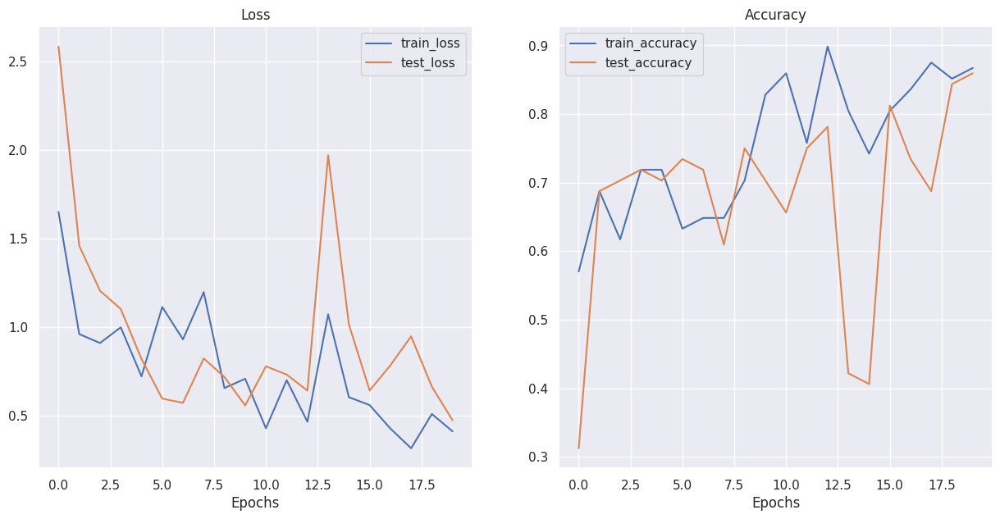

In [30]:
# Plot the training progress.
# Discuss the resulting four curves with your GSI.
# Which is the best curve to assess whether this entire project was a success?
# We will refer to this curve as Q below.
def plot_loss_curves(results):

    results = dict(list(model_results.items()))

    # Get the loss values of the results dictionary (training and test)
    loss = results['train_loss']
    test_loss = results['test_loss']

    # Get the accuracy values of the results dictionary (training and test)
    accuracy = results['train_acc']
    test_accuracy = results['test_acc']

    # Figure out how many epochs there were
    epochs = range(len(results['train_loss']))

    # Setup a plot
    plt.figure(figsize=(15, 7))

    # Plot loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label='train_loss')
    plt.plot(epochs, test_loss, label='test_loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.legend()

    # Plot accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label='train_accuracy')
    plt.plot(epochs, test_accuracy, label='test_accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.legend();

plot_loss_curves(model_results)

### (6) Let's do a real test and ask the trained CNN to classify an arbitrary image

In [31]:
# pick any image file you like
custom_image_path = '/content/dd/training_set/paintings/2016_IMG_2335m.jpg'

import torchvision
# Load in custom image and convert the tensor values to float32
custom_image = torchvision.io.read_image(str(custom_image_path)).type(torch.float32)

# Divide the image pixel values by 255 to get them between [0, 1]
custom_image = custom_image / 255.

# Print out image data
print(f"Custom image tensor:\n{custom_image}\n")
print(f"Custom image shape: {custom_image.shape}\n")
print(f"Custom image dtype: {custom_image.dtype}")

Custom image tensor:
tensor([[[0.8980, 0.8980, 0.8941,  ..., 0.8549, 0.8549, 0.8549],
         [0.8941, 0.8902, 0.8902,  ..., 0.8549, 0.8549, 0.8549],
         [0.8863, 0.8863, 0.8863,  ..., 0.8549, 0.8549, 0.8549],
         ...,
         [0.8000, 0.8039, 0.8000,  ..., 0.7843, 0.7843, 0.7843],
         [0.8000, 0.8039, 0.8039,  ..., 0.7843, 0.7843, 0.7843],
         [0.8000, 0.8039, 0.8039,  ..., 0.7843, 0.7843, 0.7843]],

        [[0.9137, 0.9137, 0.9098,  ..., 0.8784, 0.8784, 0.8784],
         [0.9098, 0.9059, 0.9059,  ..., 0.8784, 0.8784, 0.8784],
         [0.9020, 0.9020, 0.9020,  ..., 0.8784, 0.8784, 0.8784],
         ...,
         [0.7804, 0.7843, 0.7882,  ..., 0.7843, 0.7843, 0.7843],
         [0.7804, 0.7843, 0.7922,  ..., 0.7843, 0.7843, 0.7843],
         [0.7804, 0.7843, 0.7922,  ..., 0.7843, 0.7843, 0.7843]],

        [[0.9608, 0.9608, 0.9569,  ..., 0.9333, 0.9333, 0.9333],
         [0.9569, 0.9529, 0.9529,  ..., 0.9333, 0.9333, 0.9333],
         [0.9490, 0.9490, 0.9490,  ..

In [32]:
custom_image_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
])

# Transform target image
custom_image_transformed = custom_image_transform(custom_image)

# Print out original shape and new shape
print(f"Original shape: {custom_image.shape}")
print(f"New shape: {custom_image_transformed.shape}")

Original shape: torch.Size([3, 4047, 3407])
New shape: torch.Size([3, 224, 224])


In [33]:
model.eval()
with torch.inference_mode():
    # Add an extra dimension to image
    custom_image_transformed_with_batch_size = custom_image_transformed.unsqueeze(dim=0)

    # Print out different shapes
    print(f"Custom image transformed shape: {custom_image_transformed.shape}")
    print(f"Unsqueezed custom image shape: {custom_image_transformed_with_batch_size.shape}")

    # Make a prediction on image with an extra dimension
    custom_image_pred = model(custom_image_transformed.unsqueeze(dim=0).to(device))

Custom image transformed shape: torch.Size([3, 224, 224])
Unsqueezed custom image shape: torch.Size([1, 3, 224, 224])


In [34]:
# Let's convert them from logits -> prediction probabilities -> prediction labels
# Print out prediction logits
print(f"Prediction logits: {custom_image_pred}")

# Convert logits -> prediction probabilities (using torch.softmax() for multi-class classification)
custom_image_pred_probs = torch.softmax(custom_image_pred, dim=1)
print(f"Prediction probabilities: {custom_image_pred_probs}")

# Convert prediction probabilities -> prediction labels
custom_image_pred_label = torch.argmax(custom_image_pred_probs, dim=1)
print(f"Prediction label: {custom_image_pred_label}")

custom_image_pred_class = class_names[custom_image_pred_label.cpu()] # put pred label to CPU, otherwise will error
print("Image is likely to be a",custom_image_pred_class)

Prediction logits: tensor([[ 2.6472, -2.2193]])
Prediction probabilities: tensor([[0.9924, 0.0076]])
Prediction label: tensor([0])
Image is likely to be a paintings


### (7) Let's find all sculptures in the test set that were classified erroneously as paintings

['/content/dd/test_set/sculpture/2024_IMG_0353m.jpg', '/content/dd/test_set/sculpture/2023_IMG_7415m.jpg', '/content/dd/test_set/sculpture/2024_IMG_0355m.jpg', '/content/dd/test_set/sculpture/2024_IMG_0341m.jpg', '/content/dd/test_set/sculpture/2024_IMG_7790m.jpg', '/content/dd/test_set/sculpture/2024_IMG_0863m.jpg', '/content/dd/test_set/sculpture/2024_IMG_0821m.jpg', '/content/dd/test_set/sculpture/2025_IMG_0461m.jpg', '/content/dd/test_set/sculpture/2023_IMG_7414m.jpg', '/content/dd/test_set/sculpture/2023_IMG_7411m.jpg', '/content/dd/test_set/sculpture/2024_IMG_6844m.jpg', '/content/dd/test_set/sculpture/2024_IMG_0819m.jpg', '/content/dd/test_set/sculpture/2024_IMG_0875m.jpg', '/content/dd/test_set/sculpture/2024_IMG_1087m.jpg', '/content/dd/test_set/sculpture/2025_IMG_0869m.jpg', '/content/dd/test_set/sculpture/2024_IMG_7800m.jpg', '/content/dd/test_set/sculpture/2023_IMG_7401m.jpg', '/content/dd/test_set/sculpture/2024_IMG_1072m.jpg', '/content/dd/test_set/sculpture/2024_IMG_7792

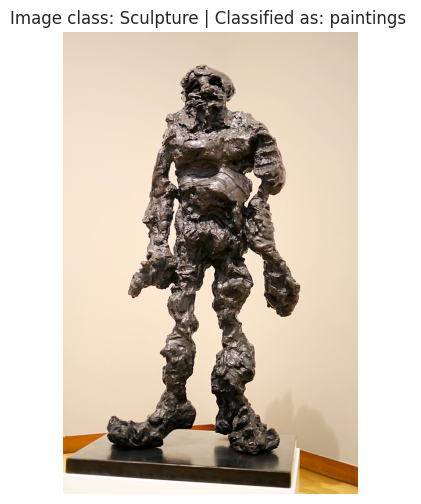

In [35]:
# First get all image files in YOUR sculptures.
# Then apply the commands from step (6) to all those images
import glob
import torchvision
from torchvision import transforms

image_path_list = glob.glob("/content/dd/test_set/sculpture/*.jpg")
print(image_path_list)

for custom_image_path in image_path_list:
    custom_image = torchvision.io.read_image(str(custom_image_path)).type(torch.float32)
    custom_image = custom_image / 255

    custom_image_transform = transforms.Compose([
        transforms.Resize(IMAGE_SIZE),
    ])

    custom_image_transformed = custom_image_transform(custom_image)

    model.eval()
    with torch.inference_mode():
        # Add an extra dimension to image
        custom_image_transformed_with_batch_size = custom_image_transformed.unsqueeze(dim=0)
        custom_image_pred = model(custom_image_transformed.unsqueeze(dim=0).to(device))
    custom_image_pred_probs = torch.softmax(custom_image_pred, dim=1)
    custom_image_pred_label = torch.argmax(custom_image_pred_probs, dim=1)
    custom_image_pred_class = class_names[custom_image_pred_label.cpu()] # put pred label to CPU, otherwise will error
    print(custom_image_path," is likely to be a",custom_image_pred_class)
    # repeat the commands from step (6) and
    # display all sculpture it classified erroneously as paintings
    if (custom_image_pred_class=='paintings'):
        img = Image.open(custom_image_path)
        img_as_array = np.asarray(img)
        plt.figure(figsize=(8, 6))
        plt.imshow(img_as_array)
        plt.title(f"Image class: Sculpture | Classified as: {custom_image_pred_class} ")
        plt.axis(False);

#### (8) Final Questions and Longer Training Runs

In [2]:
# (8A) If you have not already done so, please increase the number of epochs to 20
# and determine how high the curve Q will go.
#After 20 epochs I got these results:
#Epoch: 20 | train_loss: 0.4105 | train_acc: 0.8672 | test_loss: 0.4730 | test_acc: 0.8594

In [3]:
# (8B) 2x(50+20) images is typically not sufficient to reach high Q values.
# We recommend you repeat all steps with 2x(100+20) or 2x(200+40) images.
# Will you see an increase in Q?
#Yes you will see an increase in Q because there will be more data for the model to be trained on
# Having more data allows the model to notice more subtle differences or just classify the items better